In [1]:
import copy
from collections import namedtuple

import numba
import numpy as np
import pint
import scipy
from matplotlib import pyplot as plt
from open_atmos_jupyter_utils import show_plot

In [2]:
si = pint.UnitRegistry()
si.setup_matplotlib()
%config InlineBackend.figure_formats = ['svg']

Heat transfer in the soil

In one dimension:
$$\frac{\partial T}{\partial t} = \alpha \left(\frac{\partial^2 T}{\partial z^2} \right),$$

where

- T --- temperature [$K$],
- $\alpha = k/ c_w$ --- thermal diffusivity [$m^2/s$],
- k --- thermal conductivity coefficient [$W/m K$]
- cw --- specific heat [$J/ m^3 K$].

Thermal flux from Fourier's law:
$$J = -k \frac{\partial T}{\partial z}.$$


In [3]:
def solar_irradiance(c, t):
    return c.solar_constant * max(0, np.cos(2 * np.pi * t / c.moon_day_length))


def absorption(c, solar_irradiance):
    return (1 - c.moon_albedo) * solar_irradiance


def energy_balance(c, T1, T0, dz):
    return (
        c.moon_emmissivity * c.sigma * T0**4 - c.thermal_conductivity * (T1 - T0) / dz
    )

In [4]:
def ftcs_scheme_1D(T_new, T_old, alpha, dt, dz):
    coeff = alpha * dt / dz**2
    T_new[1:-1] = T_old[1:-1] * (1 - 2 * coeff) + coeff * (T_old[:-2] + T_old[2:])
    return T_new


def newton_raphson(c, T1, dz, irradiance, T_guess, rtol=1e-5, max_iterations=100):
    T0 = T_guess
    for i in range(max_iterations):
        f = (
            c.moon_emmissivity * c.sigma * T0**4
            - c.thermal_conductivity * (T1 - T0) / dz
            - irradiance
        )

        df = 4 * c.moon_emmissivity * c.sigma * T0**3 + c.thermal_conductivity / dz

        T_new = T0 - f / df
        if (abs(T_new - T0) / T_new) < rtol:
            return T_new

        T0 = T_new
    return T0

## Constants catalogue and simualation settings

In [5]:
Const = namedtuple(
    "Constants",
    [
        "moon_albedo",
        "solar_constant",
        "moon_day_length",
        "moon_emmissivity",
        "moon_night_temperature",
        "sigma",
        "thermal_conductivity",
        "specific_heat_capacity",
        "thermal_diffusivity",
    ],
)
constants_pint = Const(
    moon_albedo=0.12,
    solar_constant=1361 * si.W / si.m**2,
    moon_day_length=29.53 * si.days,
    moon_emmissivity=0.85,
    moon_night_temperature=100 * si.K,
    sigma=scipy.constants.Stefan_Boltzmann * si.W / si.m**2 / si.K**4,
    thermal_conductivity=(k := 0.001 * si.W / si.m / si.K),
    specific_heat_capacity=(cw := 1.2e6 * si.J / si.m**3 / si.K),
    thermal_diffusivity=k / cw,
)

In [6]:
SimulationSettings = namedtuple(
    "SimulationSettings",
    [
        "depth",
        "dt",
        "N",
        "dz",
        "z",
        "T",
    ],
)
settings = SimulationSettings(
    depth=(H := 2.0 * si.m),
    dt=120 * si.s,
    N=(N := 101),
    dz=H / (N - 1),
    z=np.linspace(0, H, N),
    T=np.zeros(N),
)

## Simualtion with possibility to enable Numba just-in-time compilation

In [7]:
def simulate(c: Const, s: SimulationSettings, days=1, ENABLE_NUMBA=False):
    T = np.ones_like(s.T) * c.moon_night_temperature
    steps_per_day = int(c.moon_day_length / s.dt)
    total_steps = days * steps_per_day

    temperatures = np.tile(T, (total_steps + 1, 1))
    times = np.arange(0, total_steps + 1) * s.dt
    T_new = copy.deepcopy(T)
    if ENABLE_NUMBA:
        ftcs_scheme = numba.njit(ftcs_scheme_1D)
        newton_raphson_scheme = numba.njit(newton_raphson)
    else:
        ftcs_scheme = ftcs_scheme_1D
        newton_raphson_scheme = newton_raphson

    for n in range(total_steps):
        I_abs = absorption(c, solar_irradiance(c, t=n * s.dt))

        T_new[:] = ftcs_scheme(T_new, T, c.thermal_diffusivity, s.dt, s.dz)
        T_new[0] = newton_raphson_scheme(c, T_new[1], s.dz, I_abs, T_guess=T[0])

        T_new[-1] = T_new[-2]
        T[:] = T_new

        temperatures[n + 1] = T

    return times, temperatures

In [8]:
def plotting(times, temperatures, z, days, plot_step=100):
    fig, ax = plt.subplots(figsize=(12, 6))

    mesh = ax.pcolormesh(
        times.to(si.days)[::plot_step],
        z,
        temperatures.T[:, ::plot_step].m,
        cmap="inferno",
        rasterized=True,
    )

    fig.colorbar(mesh, ax=ax, label=f"Temperature [{temperatures.units:~P}]")

    ax.set_title(f"Heat propagation in lunar regolith over {days} moon days")
    ax.invert_yaxis()
    return fig, ax

## Example run simulation without Numba
test run for checking units

In [9]:
times, temperatures = simulate(constants_pint, settings, days=(days := 1))

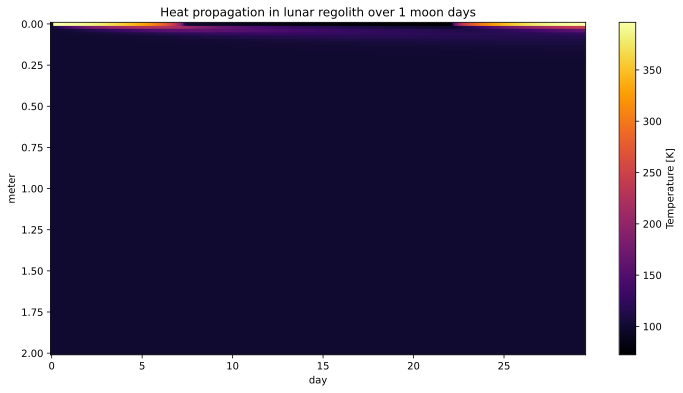

In [10]:
fig, ax = plotting(times, temperatures, settings.z, days)
show_plot("regolith", fig)

## Example run simulation with Numba enabled

In [11]:
def namedtuple_si_magnitudes(namedtuple_data, namedtuple_name):
    return namedtuple_name(
        *(
            (
                value.to_base_units().magnitude
                if isinstance(value, pint.Quantity)
                else value
            )
            for value in namedtuple_data
        )
    )

In [12]:
const_si_magnitudes = namedtuple_si_magnitudes(constants_pint, Const)
settings_si_magnitudes = namedtuple_si_magnitudes(settings, SimulationSettings)

times_numba, temperatures_numba = simulate(
    const_si_magnitudes, settings_si_magnitudes, days=(days := 100), ENABLE_NUMBA=True
)

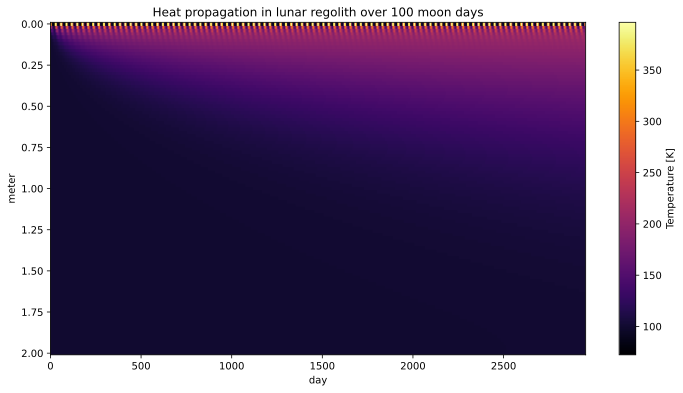

In [13]:
fig, ax = plotting(
    times_numba * si.s, temperatures_numba * si.K, settings_si_magnitudes.z * si.m, days
)
show_plot("regolith_numba", fig)